# 05 — Pré-entraînement sur TinyStories

Première phase de la méthode des vrais LLM (voir `PLAN.md`) : un
**pré-entraînement** sur beaucoup de texte simple, pour que le modèle
apprenne l'anglais et l'usage de la consigne `words: ...`. Le notebook 06
le **fine-tunera** ensuite sur les comptines.

Par rapport au notebook 02, la boucle et l'architecture restent celles du
cours. Ce qui change :

| | notebook 02 | ce notebook |
|---|---|---|
| tokens | caractères (66) | BPE GPT-2 réduit (14 122), notebook 04 |
| données | 2 682 comptines, 400 000 caractères | 54 849 histoires, 9,4 millions de tokens |
| modèle | `n_embd` 128, 4 blocs, 4 têtes | `n_embd` 256, 6 blocs, 8 têtes |
| fin de texte | `\n\n` | `<|endoftext|>` |
| nouveau | — | partage des poids, *learning rate* variable, calcul en `bfloat16` |

In [1]:
import copy
import json
import math
import random
import shutil
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, RandomSampler
from torch.utils.tensorboard import SummaryWriter

from comptines import BPETokenizer, GPTLanguageModel, TokenTextDataset, keyword_hits, write_text, write_texts

In [2]:
SEED = 1337
torch.manual_seed(SEED)
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

BPE_DIR = ROOT / "data" / "bpe"
RUNS_DIR = ROOT / "runs" / "05_preentrainement"
CHECKPOINT_PATH = ROOT / "checkpoints" / "gpt_bpe_preentraine.pt"

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"device : {device}")

device : cuda


## 1. Les données

Le vocabulaire (`vocab.json`) et les corpus en tokens du notebook 04.
`TokenTextDataset` (module `comptines.py`) est la version BPE du
`RhymeDataset` du notebook 02, avec les mêmes règles :

- un exemple = consigne + texte + `<|endoftext|>` ;
- mots-clés **tirés à nouveau à chaque passage** (fixes pour la validation) ;
- cibles à `-1` sur la consigne et le remplissage : la loss les ignore.

On garde aussi la validation des **comptines** : on y mesurera la loss sans
jamais entraîner dessus, pour voir ce que TinyStories apprend d'utile pour
les comptines avant même le fine-tuning.

In [3]:
tokenizer = BPETokenizer(json.loads((BPE_DIR / "vocab.json").read_text()))
block_size = 256

train_dataset = TokenTextDataset(torch.load(BPE_DIR / "tinystories_train.pt"), tokenizer, block_size)
val_dataset = TokenTextDataset(torch.load(BPE_DIR / "tinystories_val.pt"), tokenizer, block_size, fixed_keywords=True)
rhymes_val_dataset = TokenTextDataset(torch.load(BPE_DIR / "comptines_val.pt"), tokenizer, block_size,
                                      fixed_keywords=True)
print(f"vocab_size : {tokenizer.vocab_size:,}")
print(f"{len(train_dataset):,} histoires d'entraînement   {len(val_dataset):,} de validation   "
      f"{len(rhymes_val_dataset):,} comptines de validation")

vocab_size : 14,122
54,849 histoires d'entraînement   5,594 de validation   299 comptines de validation


In [4]:
x0, y0 = train_dataset[0]
n = int((y0 != -1).nonzero().max()) + 1
pieces = [tokenizer.decode([t]) for t in x0[:n].tolist()]
targets = ["·" if t == -1 else tokenizer.decode([t]) for t in y0[:n].tolist()]
print("x :", pieces[:20], "...")
print("y :", targets[:20], "...")
print(f"\n{(y0 != -1).sum().item()} positions notées sur {block_size} ; dernière cible : {targets[-1]!r}")

x : ['words', ':', ' showed', ',', ' wow', ',', ' couldn', '\n', 'Once', ' upon', ' a', ' time', ' there', ' was', ' a', ' little', ' boy', ' named', ' Ben', '.'] ...
y : ['·', '·', '·', '·', '·', '·', '·', 'Once', ' upon', ' a', ' time', ' there', ' was', ' a', ' little', ' boy', ' named', ' Ben', '.', ' Ben'] ...

182 positions notées sur 256 ; dernière cible : '<|endoftext|>'


Même décalage d'un cran qu'au script 06 : la cible de la position `t` est
le token `t + 1`. La consigne est lue mais pas notée, et la dernière cible est
`<|endoftext|>` : le modèle apprend à finir son histoire.

### Les lots

`batch_size = 32` exemples de 256 tokens : 8 192 positions par pas.

In [5]:
batch_size = 32
eval_every = 500
val_batches = 25


def make_loader(dataset: TokenTextDataset, n_batches: int) -> DataLoader:
    """Un `DataLoader` qui tire `n_batches` lots au hasard, avec remise."""
    sampler = RandomSampler(dataset, replacement=True, num_samples=n_batches * batch_size)
    return DataLoader(dataset, batch_size=batch_size, sampler=sampler)


val_loader = make_loader(val_dataset, val_batches)
rhymes_val_loader = make_loader(rhymes_val_dataset, 10)

## 2. Le modèle

Le GPT du script 06, plus grand : `n_embd` 256, 6 blocs de 8 têtes (de 32
dimensions chacune, comme avant), `block_size` 256 tokens, `dropout` 0.1 (on
a 20 fois plus de données qu'au notebook 02, le risque de réciter le corpus
est plus faible).

### Le partage des poids (*weight tying*)

Avec 14 122 tokens, deux matrices deviennent énormes :

- l'**embedding de token** `(vocab_size, n_embd)` : token → vecteur ;
- la **couche de sortie** `lm_head` `(n_embd → vocab_size)` : vecteur → score
  de chaque token.

Elles font le même travail dans les deux sens : relier les tokens et
l'espace des vecteurs. GPT-2 utilise **la même matrice** pour les deux
(Press et Wolf, 2017). Deux avantages : 3,6 millions de paramètres en moins,
et une matrice qui apprend deux fois plus vite, puisqu'elle reçoit le
gradient de l'entrée et celui de la sortie.

Avec le partage, on initialise les poids comme GPT-2 (loi normale
d'écart-type 0,02) : l'initialisation par défaut de `nn.Embedding` (écart-type
1) donnerait des logits de départ énormes en sortie.

In [6]:
config = {"vocab_size": tokenizer.vocab_size, "block_size": block_size, "n_embd": 256, "n_head": 8,
          "n_layer": 6, "dropout": 0.1, "tie_weights": True}
model = GPTLanguageModel(**config).to(device)

n_params = sum(p.numel() for p in model.parameters())  # la matrice partagée n'est comptée qu'une fois
n_embedding = model.token_embedding_table.weight.numel()
n_blocks = sum(p.numel() for p in model.blocks.parameters())
print(f"{n_params:,} paramètres")
print(f"  embedding de token (partagé avec lm_head) : {n_embedding:,}")
print(f"  6 blocs Transformer                        : {n_blocks:,}")
print(f"  sans partage, il y en aurait               : {n_params + n_embedding:,}")

xb, yb = next(iter(make_loader(train_dataset, 1)))
with torch.no_grad():
    loss0 = model(xb.to(device), yb.to(device))[1].item()
print(f"\nloss avant entraînement : {loss0:.4f}   (ln({tokenizer.vocab_size:,}) = {math.log(tokenizer.vocab_size):.2f})")

8,429,354 paramètres
  embedding de token (partagé avec lm_head) : 3,615,232
  6 blocs Transformer                        : 4,733,952
  sans partage, il y en aurait               : 12,044,586



loss avant entraînement : 9.6398   (ln(14,122) = 9.56)


La loss de départ est proche de `ln(vocab_size)` : grâce à
l'initialisation à 0,02, le modèle commence par une distribution presque
uniforme sur les 14 122 tokens, comme il se doit.

## 3. Deux réglages des vrais pré-entraînements

### Un *learning rate* qui varie

Le cours utilise un *learning rate* constant. Les pré-entraînements (GPT-2,
GPT-3, Llama, nanoGPT) le font varier :

- **échauffement** (*warmup*) : on monte de 0 à `max_lr` pendant les premiers
  pas. Au début, les poids sont aléatoires et les gradients désordonnés : de
  grands pas risqueraient de déstabiliser l'entraînement ;
- **décroissance en cosinus** : on redescend ensuite doucement jusqu'à
  `min_lr`. En fin d'entraînement, de petits pas affinent sans abîmer ce qui
  est appris.

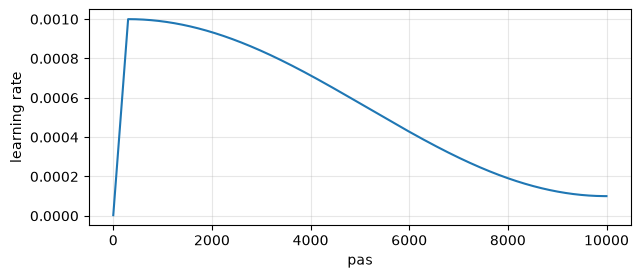

In [7]:
max_steps = 10_000

warmup_steps = 300
max_lr = 1e-3
min_lr = 1e-4


def lr_at(step: int) -> float:
    """Learning rate au pas `step` : montée linéaire, puis cosinus de `max_lr` à `min_lr`."""
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


plt.figure(figsize=(7, 2.8))
plt.plot([lr_at(s) for s in range(max_steps)])
plt.xlabel("pas")
plt.ylabel("learning rate")
plt.grid(alpha=0.3)
plt.show()

### Calculer en `bfloat16`

Par défaut, PyTorch calcule en `float32` (32 bits par nombre). Les cartes
récentes (dont la RTX 3050) calculent beaucoup plus vite en 16 bits.
`torch.autocast` fait passer les gros produits matriciels en `bfloat16` et
garde en `float32` les opérations sensibles (softmax, loss, mise à jour des
poids). Le `bfloat16` garde la même plage de valeurs que le `float32`, avec
moins de précision : ça suffit pour l'entraînement. C'est le format de calcul
des LLM actuels. Sur CPU, on reste en `float32`.

In [8]:
def autocast():
    """Calcul en bfloat16 sur GPU, rien de spécial sur CPU."""
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

## 4. L'entraînement

La boucle du notebook 03 (meilleur modèle de validation gardé de côté), avec
le *learning rate* mis à jour à chaque pas et le calcul en `bfloat16`. À
chaque mesure, on note aussi la loss sur les comptines de validation.

In [9]:
def train_step(model: nn.Module, optimizer: torch.optim.Optimizer, X: torch.Tensor, Y: torch.Tensor) -> float:
    """Un pas d'entraînement sur un lot ; renvoie la loss du lot."""
    model.train()  # dropout actif
    with autocast():
        _, loss = model(X.to(device), Y.to(device))  # 1. forward, loss comprise
    optimizer.zero_grad(set_to_none=True)
    loss.backward()  # 2. backward
    optimizer.step()  # 3. step
    return loss.item()


@torch.no_grad()
def test(model: nn.Module, loader: DataLoader) -> float:
    """Mesure la loss moyenne sur les lots du loader, sans apprendre."""
    model.eval()  # dropout coupé
    total = 0.0
    for X, Y in loader:
        with autocast():
            _, loss = model(X.to(device), Y.to(device))
        total += loss.item()
    return total / len(loader)


def run_training(model: nn.Module, run: str, max_steps: int) -> dict:
    """Entraîne pendant `max_steps` pas, mesure tous les `eval_every` pas,
    et recharge à la fin les poids du meilleur pas de validation."""
    torch.manual_seed(SEED)
    log_dir = RUNS_DIR / run
    shutil.rmtree(log_dir, ignore_errors=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr)
    train_losses, history = [], []
    best_val, best_step, best_state = float("inf"), 0, None
    start = time.perf_counter()

    with SummaryWriter(log_dir=str(log_dir)) as writer:
        for step, (X, Y) in enumerate(make_loader(train_dataset, max_steps), start=1):
            for group in optimizer.param_groups:
                group["lr"] = lr_at(step - 1)
            train_losses.append(train_step(model, optimizer, X, Y))

            if step % eval_every == 0 or step == max_steps:
                train_loss = sum(train_losses) / len(train_losses)
                val_loss = test(model, val_loader)
                rhymes_loss = test(model, rhymes_val_loader)
                writer.add_scalars("loss", {"train": train_loss, "val": val_loss, "comptines": rhymes_loss}, step)
                writer.add_scalar("lr", lr_at(step - 1), step)
                history.append((step, train_loss, val_loss, rhymes_loss))
                print(f"pas {step:>6,}   train {train_loss:.3f}   val {val_loss:.3f}   comptines {rhymes_loss:.3f}   "
                      f"{time.perf_counter() - start:>5.0f} s")
                train_losses = []
                if val_loss < best_val:
                    best_val, best_step, best_state = val_loss, step, copy.deepcopy(model.state_dict())

    duration = time.perf_counter() - start
    model.load_state_dict(best_state)
    print(f"\n[{run}] {max_steps:,} pas   {duration / 60:.0f} min   meilleure val {best_val:.4f} au pas {best_step:,}")
    return {"history": history, "best_step": best_step, "best_val": best_val, "duration": duration}

10 000 pas : 1 h 40 mesurée sur la RTX 3050 (≈ 0,6 s par pas, évaluations comprises). Les courbes sont aussi dans
TensorBoard (`uv run tensorboard --logdir runs`).

In [10]:
result = run_training(model, "gpt_bpe", max_steps)

pas    500   train 4.382   val 2.868   comptines 7.050     146 s


pas  1,000   train 2.615   val 2.375   comptines 7.235     449 s


pas  1,500   train 2.273   val 2.165   comptines 7.065     757 s


pas  2,000   train 2.098   val 2.052   comptines 7.477    1116 s


pas  2,500   train 1.979   val 1.951   comptines 7.513    1497 s


...

pas  8,000   train 1.546   val 1.603   comptines 7.535    4512 s


pas  8,500   train 1.525   val 1.612   comptines 7.683    4837 s


pas  9,000   train 1.510   val 1.579   comptines 7.472    5294 s


pas  9,500   train 1.502   val 1.600   comptines 7.586    5633 s


pas 10,000   train 1.492   val 1.596   comptines 7.533    5928 s

[gpt_bpe] 10,000 pas   99 min   meilleure val 1.5787 au pas 9,000


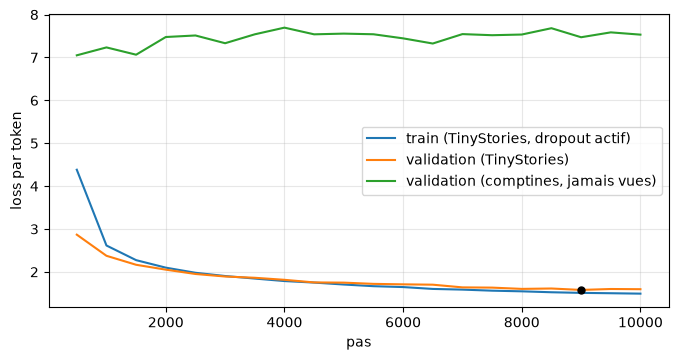

perplexité de validation : 4.8


In [11]:
steps, train_curve, val_curve, rhymes_curve = zip(*result["history"])
plt.figure(figsize=(8, 3.8))
plt.plot(steps, train_curve, label="train (TinyStories, dropout actif)")
plt.plot(steps, val_curve, label="validation (TinyStories)")
plt.plot(steps, rhymes_curve, label="validation (comptines, jamais vues)")
plt.scatter([result["best_step"]], [result["best_val"]], color="black", s=25, zorder=3)
plt.xlabel("pas")
plt.ylabel("loss par token")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"perplexité de validation : {math.exp(result['best_val']):.1f}")

La **perplexité** `exp(loss)` se lit comme au notebook 02 : le modèle hésite
en moyenne comme s'il choisissait entre ce nombre de tokens, sur 14 122
possibles.

## 5. Écrire à partir de mots

`write_text` (module `comptines.py`) : la génération du script 07
(température, top-k), qui part de la consigne et s'arrête au premier
`<|endoftext|>`. Avec 14 122 tokens au lieu de 66 caractères, on prend un
top-k plus large (40).

In [12]:
torch.manual_seed(SEED)
for words in [["cat", "moon"], ["king", "pie"], ["rain", "garden"], ["dog", "bone", "star"], ["girl", "ball", "happy"]]:
    print(f"--- {', '.join(words)} ---")
    print(write_text(model, tokenizer, words), end="\n\n")

--- cat, moon ---


Once upon a time, there was a kind man named Tom. He had a big house and many toys. Tom liked to play with his toys and have fun with his toys.
One day, a new toy came to Tom's house. It was a small, red ball. Tom had a question to play with the new toy. He blinked at the ball and said, "Hi, play with me!"
The new toy said, "Yes, I like your new toy!" So, Tom played with the new toy all day. He poked it with his paw and it made a fun sound. Tom was very happy with his new toy.

--- king, pie ---


Once upon a time, in a big forest, there was a pretty flower. The flower was very pretty. Every day, the flower would bloom and sing. It was very happy in the sun.
One day, a big, mean wolf came to the forest. The wolf wanted to eat the flower. The wolf was sad. It did not know it was their friend. The flower was too big for the wolf.
The pretty flower had an idea. It told the wolf, "You must share the flower with others. If you share, let us be friends." The wolf agreed. They shared the flower and had a fun party. The flower was happy and its friends were happy too. They all lived happily ever after.

--- rain, garden ---


Once upon a time, there was a little girl named Lily. She loved to play outside in the sun. One day, she saw a big, red ball in the garden. Lily was very happy and wanted to play with it.
Lily had an idea. She would use her hands to pick the ball. She picked it up and put it in her hands. She was very careful with the ball. When she was done, the ball started to move! It was very unexpected!
Lily and her mom were surprised. They didn't know what to do. A little bird flew down and picked up the ball in its beak. The bird was surprised and said, "Thank you, Lily!" Then, the bird gave the ball back to Lily. They both were very surprised and happy. The bird became their new friend, and they played together all day long.

--- dog, bone, star ---


Once upon a time, there was a little girl named Lily. She had a toy that was a big, shiny coin. Lily loved her coin very much. She would keep it close to her when she did it.
One day, Lily's friend, Tim, came to play. Tim had a big, shiny ball. Lily wanted to play with it too. Tim saw the shiny coin and wanted to try it. He put the coin on his head and said, "Lily, I want it!" Lily didn't know what to do. She said, "No, thank you. I will keep my coin close."
Tim was sad, but Lily did not give up. She kept the coin safe. Later, Lily told Tim, "You need help. I want to put it away." Tim said, "Okay, Lily. We can share it."
They took the shiny coin and played together. Tim was happy because he did not have a good job. Lily learned that sharing is good. From that day on, Lily was more careful with her friends.

--- girl, ball, happy ---


Once upon a time, there was a big, modern house with a house. In the house lived a girl named Sue and her dog, Spot. Sue liked to play with Spot all day long. They had a lot of fun together.
One day, Sue and Spot went to the store. Sue saw a big, dark automobile car. She wanted to play with it. Spot barked loudly as the loud automobile. Sue did not want to leave the car. She thought it was a fun idea.
Sue and Spot decided to clean the automobile. They worked together, and the lights went through the warm automobile. They were happy. Sue said goodbye to the automobile and went home. Sue had a great day playing with her new car and the big, modern automobile.



## 6. Le modèle utilise-t-il les mots ?

La mesure du notebook 02 (taux de reprise, et référence avec la consigne
d'un autre texte), sur 300 histoires de validation et sur les 299 comptines
de validation. `write_texts` génère toutes les consignes de même longueur en
un seul lot (32 au plus), bien plus vite qu'une consigne à la fois.

In [13]:
def evaluate_keywords(dataset: TokenTextDataset, n: int) -> tuple[float, float]:
    """Taux de reprise des mots-clés fixes des `n` premiers textes, et la référence."""
    keyword_sets = [k for k in (dataset.keywords_of(i) for i in range(min(n, len(dataset)))) if k]
    torch.manual_seed(SEED)
    generated = write_texts(model, tokenizer, keyword_sets)
    hits = sum(keyword_hits(k, g) for k, g in zip(keyword_sets, generated)) / len(generated)
    shifted = generated[1:] + generated[:1]  # le texte écrit pour une AUTRE consigne
    baseline = sum(keyword_hits(k, g) for k, g in zip(keyword_sets, shifted)) / len(generated)
    return hits, baseline


keyword_scores = {}
for name, dataset in [("histoires", val_dataset), ("comptines", rhymes_val_dataset)]:
    keyword_scores[name] = evaluate_keywords(dataset, 300)
    hits, baseline = keyword_scores[name]
    print(f"{name:10} taux de reprise {hits:6.1%}   référence {baseline:5.1%}")
print("\nrappel, modèle caractère du notebook 02 (comptines) : 17,2 %   référence 1,9 %")

histoires  taux de reprise  42.7%   référence 21.7%


comptines  taux de reprise  17.3%   référence  6.5%

rappel, modèle caractère du notebook 02 (comptines) : 17,2 %   référence 1,9 %


## 7. Sauvegarder

Le format des notebooks précédents, avec le vocabulaire réduit (`gpt2_ids`)
à la place de la liste des caractères. Le notebook 06 recharge ce fichier
pour le fine-tuning.

In [14]:
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save({
    "model_state": model.state_dict(),
    "config": config,
    "gpt2_ids": tokenizer.gpt2_ids,
    "val_loss": result["best_val"],
    "history": result["history"],
    "keyword_scores": keyword_scores,
}, CHECKPOINT_PATH)
print(f"→ {CHECKPOINT_PATH.relative_to(ROOT)}")

→ checkpoints\gpt_bpe_preentraine.pt
